<div style="background:linear-gradient(135deg,#2b0f27 0%,#5c2250 45%,#a64d8f 100%);color:white;padding:34px 30px;border-radius:12px;font-family:'Trebuchet MS','Segoe UI',sans-serif;"><div style="font-size:15px;letter-spacing:3px;color:#f0c6e3">PROYECTO · TALLER II · CIENCIA DE DATOS</div><div style="font-size:32px;font-weight:bold;margin:10px 0">🛍️ Lencería Lizzy: predicción de unidades vendidas por día, lugar y tipo de prenda</div><div style="font-size:18px;color:#fbe3f3">Regresión supervisada: comparación de modelos, optimización y exportación del pipeline</div><hr style="border:0;border-top:1px solid #d08abd;margin:18px 0"><div style="font-size:17px"><b>Autora:</b> Lizzy Leyla Baron Barrero<br><b>Carrera:</b> Ing. Informática · UAJMS · Yacuiba<br><b>Datos:</b> ventas <u>ESTIMADAS</u> (reconstruidas) de agosto a noviembre de 2026, exportadas desde la base del sistema (<code>datos/ventas_lineas.csv</code>)</div></div>

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Limitación que se declara desde el inicio</b><br>Las ventas de agosto a noviembre de 2026 <b>no fueron registradas por el sistema en uso real</b>: se <b>reconstruyeron de memoria</b> (con el visto bueno del docente) y se importaron con un comando, marcadas con <code>origen = 'estimado'</code>. Por eso el modelo aprende las <b>reglas con las que se reconstruyeron los datos</b> (volumen diario, qué se vendía en cada mes, etc.). Este trabajo demuestra que <b>el flujo completo funciona</b> (datos → preparación → modelos → optimización → exportación → inferencia), <b>no que el modelo prediga el negocio real</b>. Entrenarlo con ventas registradas por el sistema queda como trabajo futuro.</div>

<div style="border-left:6px solid #6a3d9a;background:#6a3d9a14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#6a3d9a">📋 🎯 Cumplimiento de la rúbrica del proyecto</b><br><table style="border-collapse:collapse;width:100%;font-size:14px"><tr style="background:#5c2250;color:white"><th style="padding:6px;text-align:left">Criterio</th><th style="padding:6px;text-align:left">Dónde se cumple</th></tr><tr><td style="padding:5px;border-bottom:1px solid #ccd">1. Dataset y preparación</td><td style="padding:5px;border-bottom:1px solid #ccd">Secciones 2 a 5: limpieza y verificación, tipo de prenda, tabla diaria con ceros, codificación One-Hot, escalado y división por días (sin fuga de datos; todo el preprocesamiento va dentro del pipeline).</td></tr><tr><td style="padding:5px;border-bottom:1px solid #ccd">2. Varios algoritmos y métricas</td><td style="padding:5px;border-bottom:1px solid #ccd">Sección 6: modelo de referencia, Ridge, Random Forest y Gradient Boosting; RMSE, MAE y R².</td></tr><tr><td style="padding:5px;border-bottom:1px solid #ccd">3. Optimización</td><td style="padding:5px;border-bottom:1px solid #ccd">Secciones 6 y 7: validación cruzada por grupos (GroupKFold por día), GridSearchCV y elección justificada del mejor modelo.</td></tr><tr><td style="padding:5px;border-bottom:1px solid #ccd">4. Exportación e inferencia</td><td style="padding:5px;border-bottom:1px solid #ccd">Sección 9 (<code>modelo_ventas.joblib</code> con el pipeline completo, verificado) y notebook aparte <code>Inferencia_Ventas_Lizzy.ipynb</code>.</td></tr><tr><td style="padding:5px">5. Defensa oral</td><td style="padding:5px">Cada decisión está explicada en las cajas «Qué se hace y por qué» y «Cómo leer esto», y las limitaciones se declaran en la sección 10.</td></tr></table></div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Cómo ejecutarlo</b><br>Colocar <code>ventas_lineas.csv</code> en la <b>misma carpeta</b> que este notebook (o en <code>datos/</code>), y usar <i>Kernel → Restart &amp; Run All</i>. Al terminar se crean <code>modelo_ventas.joblib</code>, <code>dataset_diario.csv</code> y la carpeta <code>salidas_extra/</code>. Entorno: <code>pip install -r requirements.txt</code>.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 0. Configuración inicial</div>

In [1]:
import warnings, joblib, sklearn, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
OUT = Path("salidas_extra"); OUT.mkdir(exist_ok=True)      # archivos auxiliares
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", None)

FUENTE = "font-family:'Trebuchet MS','Segoe UI',sans-serif;"
def nota(titulo, cuerpo, color="#0e7c86", icono="🔎"):
    display(HTML(f'<div style="border-left:6px solid {color};background:{color}14;padding:12px 16px;margin:8px 0;'
                 f'border-radius:6px;{FUENTE}line-height:1.55"><b style="color:{color}">{icono} {titulo}</b><br>{cuerpo}</div>'))

def mostrar(d, alto=360):
    """Tabla completa dentro de un recuadro con scroll."""
    estilo = ("<style>.tabla{border-collapse:collapse;font-size:12px}.tabla th{position:sticky;top:0;background:#5c2250;"
              "color:white;padding:4px 8px}.tabla td{padding:3px 8px;border-bottom:1px solid #eadbe6;white-space:nowrap}</style>")
    cuerpo = d.to_html(max_rows=None, classes="tabla", border=0, na_rep="", float_format=lambda v: f"{v:.5g}")
    display(HTML(estilo + f'<div style="max-height:{alto}px;overflow:auto;border:2px solid #5c2250;border-radius:6px">{cuerpo}</div>'))

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.1.1 | scikit-learn 1.9.1


<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 1. Introducción, objetivo y justificación</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Contexto</b><br><b>Lencería Lizzy</b> es un negocio familiar de ropa de la ciudad de Yacuiba que vende en el <b>Mercado Lourdes</b> y en la <b>Feria de Barrio Nuevo</b>, y también por catálogo en línea. Las compras de mercadería se deciden con la intuición de la dueña. Un registro ordenado de lo que se vende cada día permite ver patrones (qué tipo de prenda se vende más, en qué lugar y en qué época) y apoyar la decisión de <b>qué mercadería comprar en cada temporada</b>.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Objetivo del modelo</b><br>Construir y comparar modelos de <b>regresión</b> que predigan las <b>unidades vendidas</b> por <b>día</b>, <b>lugar de venta</b> y <b>tipo de prenda</b>, y elegir el mejor con métricas justificadas (RMSE, MAE y R²).</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Objetivos específicos</b><br><ul><li>Preparar un dataset diario por tipo de prenda a partir de las líneas de pedido exportadas desde la base de datos.</li><li>Entrenar y comparar varios algoritmos con validación cruzada por grupos (por día) para no filtrar información entre entrenamiento y prueba.</li><li>Optimizar hiperparámetros con búsqueda en malla y elegir el mejor modelo de forma justificada.</li><li>Exportar el pipeline completo a <code>.joblib</code> y usarlo desde un notebook de inferencia independiente.</li></ul></div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 2. Datos: de la base de datos al archivo CSV</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>El archivo <code>ventas_lineas.csv</code> lo genera el comando <code>python manage.py exportar_dataset_ventas</code> del sistema. Tiene <b>una fila por línea de pedido</b>, excluye los pedidos de prueba (<code>origen = 'prueba'</code>) y los cancelados. Aquí se lee, se verifica que las columnas esperadas existan y se comprueban los totales contra los del sistema.</div>

In [2]:
def buscar_csv():
    for nombre in ["ventas_lineas.csv", "datos/ventas_lineas.csv", "../datos/ventas_lineas.csv"]:
        if Path(nombre).exists(): return Path(nombre)
    return None

ruta = buscar_csv()
if ruta is None:
    raise FileNotFoundError("No se encontró 'ventas_lineas.csv'. Copiarlo junto a este notebook (o a una carpeta 'datos').")

lineas = pd.read_csv(ruta, parse_dates=["fecha"])
COLUMNAS = ["pedido_id", "fecha", "lugar_venta", "origen", "producto", "categoria", "subcategoria", "cantidad", "precio_unitario", "subtotal"]
faltan = [c for c in COLUMNAS if c not in lineas.columns]
assert not faltan, f"Faltan columnas en el CSV: {faltan}"

print(f"Archivo : {ruta.resolve()}")
print(f"Filas   : {len(lineas):,}  (una por línea de pedido)   Columnas: {lineas.shape[1]}")
print(f"Pedidos : {lineas['pedido_id'].nunique():,}   Prendas: {lineas['cantidad'].sum():,}   Subtotal: Bs {lineas['subtotal'].sum():,.2f}")
print(f"Fechas  : {lineas['fecha'].min().date()} a {lineas['fecha'].max().date()}   Días distintos: {lineas['fecha'].nunique()}")
print("Orígenes presentes:", lineas["origen"].value_counts().to_dict())
assert (lineas["origen"] != "prueba").all(), "El CSV contiene pedidos de prueba: no deben entrenar el modelo."
print("Valores ausentes por columna:", int(lineas[COLUMNAS].isna().sum().sum()))
mostrar(lineas.head(8), 260)

Archivo : /home/touken/Lencer-a_Lizzy/datos/ventas_lineas.csv
Filas   : 375  (una por línea de pedido)   Columnas: 19
Pedidos : 249   Prendas: 390   Subtotal: Bs 7,774.90
Fechas  : 2026-08-03 a 2026-11-17   Días distintos: 29
Orígenes presentes: {'estimado': 375}
Valores ausentes por columna: 0


,pedido_id,fecha,dia_semana,mes,semana_iso,hora,lugar_venta,origen,producto_id,producto,categoria,subcategoria,temporada,talla,color,cantidad,precio_unitario,subtotal,metodo_pago
0,313,2026-08-03,lunes,8,32,9,mercado_lourdes,estimado,15,Hilo Dental,Mujer,Abajo,todo_el_anio,S,rosa,1,14.7,14.7,efectivo
1,314,2026-08-03,lunes,8,32,11,mercado_lourdes,estimado,43,Calzón faja,Mujer,Abajo,todo_el_anio,L,verde,1,25,25,efectivo
2,314,2026-08-03,lunes,8,32,11,mercado_lourdes,estimado,48,Calzón clasico,Mujer,Abajo,todo_el_anio,M,azul,1,15,15,efectivo
3,315,2026-08-03,lunes,8,32,13,mercado_lourdes,estimado,45,Medias Antideslizantes,Otros,Medias,todo_el_anio,M,gris,1,20,20,efectivo
4,316,2026-08-03,lunes,8,32,15,mercado_lourdes,estimado,22,Bóxer suelto,Hombre,Boxer,todo_el_anio,UNICA,azul,1,19.6,19.6,efectivo
5,316,2026-08-03,lunes,8,32,15,mercado_lourdes,estimado,29,Corpiño,Mujer,Abajo,todo_el_anio,S,amarillo,1,35,35,efectivo
6,316,2026-08-03,lunes,8,32,15,mercado_lourdes,estimado,36,Medias,Otros,Medias,todo_el_anio,M,negro,1,10,10,efectivo
7,317,2026-08-03,lunes,8,32,16,mercado_lourdes,estimado,48,Calzón clasico,Mujer,Abajo,todo_el_anio,S,blanco,1,15,15,efectivo


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Las cifras deben coincidir con las del sistema (en la última exportación: 375 líneas, 249 pedidos, 390 prendas, 29 días y Bs 7.774,90). Si el notebook se ejecuta con un CSV distinto, los números cambiarán, pero la lógica es la misma. El <code>assert</code> garantiza que no se mezclaron pedidos de prueba con las ventas estimadas.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 3. Tipo de prenda</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>La base de datos organiza el catálogo por categoría (Mujer, Hombre, Otros) y subcategoría, pero para predecir interesa el <b>tipo de prenda</b> tal como se compra y se vende: ropa interior de mujer, cacheteros, hombre, niño, ropa usada, ropa de baño y medias. Ese tipo <b>no existe en la base</b>: se define aquí con un diccionario producto → tipo. Un <code>assert</code> verifica que ningún producto quede sin tipo.</div>

In [3]:
MAPEO = {
    # ropa interior de mujer
    "Boyshort": "ropa_interior_mujer", "Calzón clasico": "ropa_interior_mujer", "Calzón faja": "ropa_interior_mujer",
    "Colalé": "ropa_interior_mujer", "Corpiño": "ropa_interior_mujer", "Culotte": "ropa_interior_mujer",
    "Fajas": "ropa_interior_mujer", "Hilo Dental": "ropa_interior_mujer", "Tanga": "ropa_interior_mujer",
    "Bandeau top sin tiros": "ropa_interior_mujer", "Corpiño sin armado": "ropa_interior_mujer",
    "Cubre pezón": "ropa_interior_mujer", "Tirantes": "ropa_interior_mujer", "Top clásico": "ropa_interior_mujer",
    # cacheteros
    "Cachetero Liso": "cacheteros", "Cachetero con diseño": "cacheteros",
    # hombre
    "Brief": "hombre", "Bóxer ajustado (Boxer Brief)": "hombre", "Bóxer suelto": "hombre", "Slip": "hombre",
    # niño
    "Bóxer infantil": "nino", "Calzocillo de niño": "nino", "Medias infantiles": "nino",
    # ropa usada (mujer y hombre)
    "Ropa usada": "ropa_usada",
    # ropa de baño
    "Bikini": "ropa_de_bano", "Biquini usado": "ropa_de_bano", "Maya usada": "ropa_de_bano", "Traje de baño usado": "ropa_de_bano",
    # medias y pañuelos
    "Medias": "medias", "Medias Antideslizantes": "medias", "Medias de marca": "medias", "Pañuelos": "medias",
}
lineas["tipo"] = lineas["producto"].map(MAPEO)
sin_tipo = lineas.loc[lineas["tipo"].isna(), "producto"].unique()
assert len(sin_tipo) == 0, f"Productos sin tipo asignado: {list(sin_tipo)}"

resumen_tipo = (lineas.groupby("tipo").agg(lineas=("cantidad", "size"), prendas=("cantidad", "sum"),
                primera_venta=("fecha", "min"), ultima_venta=("fecha", "max")).reset_index())
resumen_tipo["primera_venta"] = resumen_tipo["primera_venta"].dt.date
resumen_tipo["ultima_venta"] = resumen_tipo["ultima_venta"].dt.date
mostrar(resumen_tipo, 260)

,tipo,lineas,prendas,primera_venta,ultima_venta
0,cacheteros,33,33,2026-08-05,2026-11-17
1,hombre,48,50,2026-08-03,2026-11-17
2,medias,55,60,2026-08-03,2026-11-17
3,nino,13,13,2026-08-03,2026-10-06
4,ropa_de_bano,72,72,2026-09-22,2026-11-17
5,ropa_interior_mujer,116,124,2026-08-03,2026-11-17
6,ropa_usada,38,38,2026-09-08,2026-11-17


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada fila es un tipo de prenda con cuántas líneas y prendas se vendieron y entre qué fechas. Se ve, por ejemplo, que <b>ropa de baño</b> y <b>ropa usada</b> aparecen recién desde septiembre: antes de esa fecha no existían en el negocio, y eso condiciona cómo se arman los ceros en la sección siguiente.</div>

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Decisiones del mapeo que conviene poder defender</b><br><ul><li><b>Pañuelos</b> va con <b>medias</b>: es la categoría «Otros» y tiene pocas ventas.</li><li><b>Medias infantiles</b> va con <b>niño</b>, no con medias.</li><li><b>Bikini</b> va con <b>ropa de baño</b>: es un traje de baño, no ropa interior.</li></ul></div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 4. Tabla diaria con ceros</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>El modelo necesita <b>una fila por día, lugar y tipo de prenda</b>, incluyendo los casos donde <b>no se vendió nada</b> (unidades = 0). Si se dejaran solo las filas con ventas, el modelo creería que siempre se vende algo. Reglas para los ceros:<ul><li>Solo cuentan las <b>jornadas reales</b> (pares fecha + lugar donde hubo ventas): no se inventan días en que no se salió a vender.</li><li>Cada tipo entra a la tabla <b>desde su primera venta</b>: la ropa de baño no tiene ceros en agosto porque todavía no se vendía.</li></ul></div>

In [4]:
unidades = (lineas.groupby(["fecha", "lugar_venta", "tipo"], as_index=False)["cantidad"].sum().rename(columns={"cantidad": "unidades"}))
inicio = lineas.groupby("tipo")["fecha"].min().rename("inicio").reset_index()
jornadas = lineas[["fecha", "lugar_venta"]].drop_duplicates()

grilla = jornadas.merge(inicio, how="cross")
grilla = grilla[grilla["fecha"] >= grilla["inicio"]].drop(columns="inicio")

diario = grilla.merge(unidades, on=["fecha", "lugar_venta", "tipo"], how="left")
diario["unidades"] = diario["unidades"].fillna(0).astype(int)
diario = diario.sort_values(["fecha", "lugar_venta", "tipo"]).reset_index(drop=True)

assert diario["unidades"].sum() == lineas["cantidad"].sum(), "Se perdieron unidades al armar la tabla diaria"
print(f"Filas de la tabla diaria: {len(diario)}  |  jornadas: {len(jornadas)}  |  tipos: {diario['tipo'].nunique()}")
print(f"Unidades totales: {diario['unidades'].sum()} (iguales a las del CSV)  |  filas con 0 unidades: {(diario['unidades'] == 0).sum()} "
      f"({(diario['unidades'] == 0).mean():.0%})")
print("\nInicio de cada tipo:"); print(inicio.assign(inicio=inicio["inicio"].dt.date).to_string(index=False))
mostrar(diario.groupby("tipo")["unidades"].agg(filas="count", total="sum", promedio="mean", maximo="max").round(2).reset_index(), 260)

Filas de la tabla diaria: 163  |  jornadas: 29  |  tipos: 7
Unidades totales: 390 (iguales a las del CSV)  |  filas con 0 unidades: 46 (28%)

Inicio de cada tipo:
               tipo     inicio
         cacheteros 2026-08-05
             hombre 2026-08-03
             medias 2026-08-03
               nino 2026-08-03
       ropa_de_bano 2026-09-22
ropa_interior_mujer 2026-08-03
         ropa_usada 2026-09-08


,tipo,filas,total,promedio,maximo
0,cacheteros,27,33,1.22,7
1,hombre,29,50,1.72,4
2,medias,29,60,2.07,7
3,nino,29,13,0.45,2
4,ropa_de_bano,9,72,8,12
5,ropa_interior_mujer,29,124,4.28,9
6,ropa_usada,11,38,3.45,6


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada fila de <code>diario</code> responde: <i>«¿cuántas unidades de este tipo se vendieron ese día en ese lugar?»</i>. La suma de unidades es idéntica a la del CSV (se verifica con <code>assert</code>). El <b>porcentaje de ceros</b> indica cuántas combinaciones día-tipo no tuvieron ventas: es lo normal en un negocio pequeño y lo que hace útil predecir.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 5. Variables, análisis exploratorio y división sin fuga de datos</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Variables de entrada (features): <b>lugar</b>, <b>día de la semana</b>, <b>mes</b>, <b>semana ISO</b>, <b>tipo de prenda</b> e <b>indicador de temporada de calor</b>. El indicador vale 1 desde el <b>22 de septiembre de 2026</b> (inicio de la primavera). Es un supuesto propio, no un dato medido. La variable a predecir es <b>unidades</b>.</div>

In [5]:
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
FECHA_CALOR = pd.Timestamp("2026-09-22")

diario["dia_semana"] = diario["fecha"].dt.dayofweek.map(dict(enumerate(DIAS)))
diario["mes"] = diario["fecha"].dt.month
diario["semana_iso"] = diario["fecha"].dt.isocalendar().week.astype(int)
diario["calor"] = (diario["fecha"] >= FECHA_CALOR).astype(int)

FEATS_CAT = ["lugar_venta", "dia_semana", "tipo"]
FEATS_NUM = ["mes", "semana_iso"]
FEATS_BIN = ["calor"]
FEATS = FEATS_CAT + FEATS_NUM + FEATS_BIN

X = diario[FEATS].copy()
y = diario["unidades"]
grupos = diario["fecha"].dt.strftime("%Y-%m-%d")        # un grupo = un día: todas las filas de un día van juntas

diario.to_csv("dataset_diario.csv", index=False)
print("Dataset diario guardado en dataset_diario.csv")
mostrar(diario.head(10), 280)

Dataset diario guardado en dataset_diario.csv


,fecha,lugar_venta,tipo,unidades,dia_semana,mes,semana_iso,calor
0,2026-08-03,mercado_lourdes,hombre,1,lunes,8,32,0
1,2026-08-03,mercado_lourdes,medias,2,lunes,8,32,0
2,2026-08-03,mercado_lourdes,nino,1,lunes,8,32,0
3,2026-08-03,mercado_lourdes,ropa_interior_mujer,7,lunes,8,32,0
4,2026-08-04,mercado_lourdes,hombre,3,martes,8,32,0
5,2026-08-04,mercado_lourdes,medias,0,martes,8,32,0
6,2026-08-04,mercado_lourdes,nino,1,martes,8,32,0
7,2026-08-04,mercado_lourdes,ropa_interior_mujer,6,martes,8,32,0
8,2026-08-05,mercado_lourdes,cacheteros,1,miércoles,8,32,0
9,2026-08-05,mercado_lourdes,hombre,2,miércoles,8,32,0


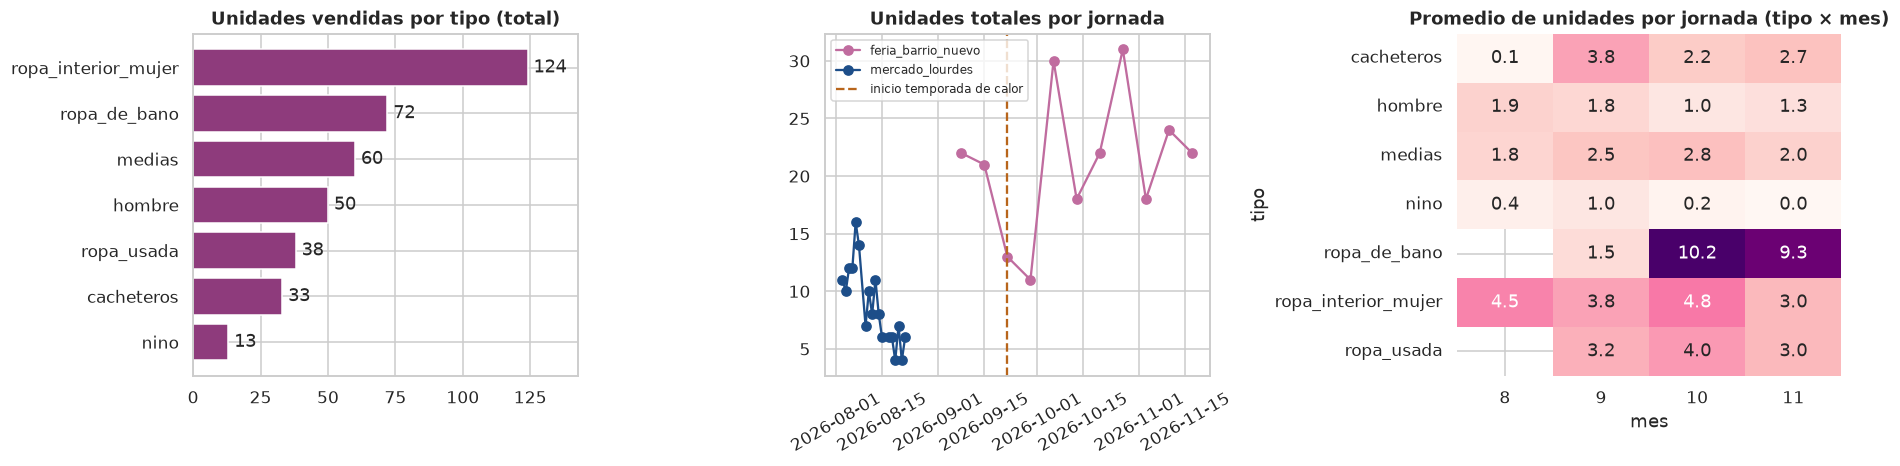

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))

tot = diario.groupby("tipo")["unidades"].sum().sort_values()
b = ax[0].barh(tot.index, tot.values, color="#8e3b7c")
for r in b: ax[0].text(r.get_width(), r.get_y() + r.get_height() / 2, f" {int(r.get_width())}", va="center")
ax[0].set_title("Unidades vendidas por tipo (total)"); ax[0].set_xlim(0, tot.max() * 1.15)

dia = diario.groupby(["fecha", "lugar_venta"])["unidades"].sum().reset_index()
for lugar, col in zip(sorted(dia["lugar_venta"].unique()), ["#c06c9f", "#1d4e89", "#0e7c86"]):
    s = dia[dia["lugar_venta"] == lugar]; ax[1].plot(s["fecha"], s["unidades"], "o-", label=lugar, color=col)
ax[1].axvline(FECHA_CALOR, color="#b8651b", ls="--", label="inicio temporada de calor")
ax[1].set_title("Unidades totales por jornada"); ax[1].legend(fontsize=8); ax[1].tick_params(axis="x", rotation=30)

piv = diario.pivot_table(index="tipo", columns="mes", values="unidades", aggfunc="mean")
sns.heatmap(piv, annot=True, fmt=".1f", cmap="RdPu", ax=ax[2], cbar=False)
ax[2].set_title("Promedio de unidades por jornada (tipo × mes)")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br><b>Izquierda:</b> qué tipos se venden más en total. <b>Centro:</b> el volumen de cada jornada; se ve que Lourdes (agosto) y Barrio Nuevo (martes, desde septiembre) son periodos distintos. <b>Derecha:</b> el promedio por tipo y mes; los espacios vacíos son tipos que todavía no se vendían ese mes. Esta vista justifica incluir tipo, mes y temporada de calor como variables.</div>

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Variables que se confunden entre sí (para la defensa)</b><br>Lourdes solo existe en <b>agosto</b> (lunes a sábado) y Barrio Nuevo solo desde <b>septiembre</b> y solo los <b>martes</b>. Por eso <i>lugar</i>, <i>mes</i>, <i>día de la semana</i> y <i>temporada de calor</i> están casi mezclados, y el modelo <b>no puede separar sus efectos</b> con estos datos. Es una consecuencia de cómo se reconstruyeron las ventas, no un error del código.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br><b>División sin fuga de datos.</b> Se separa el 20 % de los <b>días</b> (no de las filas) para prueba. Si se separaran filas al azar, el modelo vería otros tipos del mismo día en el entrenamiento y la evaluación saldría optimista. Con solo ~29 jornadas, una división puede quedar desbalanceada, así que se busca una semilla (de forma determinista) donde la prueba tenga <b>ambos lugares</b> y <b>días con y sin calor</b>.</div>

In [7]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

for semilla in range(RANDOM_STATE, RANDOM_STATE + 500):
    i_tr, i_te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla).split(X, y, grupos))
    te = diario.iloc[i_te]
    if te["lugar_venta"].nunique() == 2 and te["calor"].nunique() == 2 and (te["unidades"] > 0).sum() >= 15:
        break

X_tr, X_te, y_tr, y_te = X.iloc[i_tr], X.iloc[i_te], y.iloc[i_tr], y.iloc[i_te]
g_tr = grupos.iloc[i_tr]
assert set(grupos.iloc[i_tr]).isdisjoint(set(grupos.iloc[i_te])), "Hay días repetidos entre entrenamiento y prueba"

print(f"Semilla usada: {semilla}")
print(f"Entrenamiento: {len(X_tr)} filas en {g_tr.nunique()} días  |  Prueba: {len(X_te)} filas en {grupos.iloc[i_te].nunique()} días")
print("Días de prueba:", sorted(grupos.iloc[i_te].unique()))
print("Lugares en prueba:", te["lugar_venta"].value_counts().to_dict())

Semilla usada: 42
Entrenamiento: 129 filas en 23 días  |  Prueba: 34 filas en 6 días
Días de prueba: ['2026-08-12', '2026-08-13', '2026-08-17', '2026-08-21', '2026-10-06', '2026-11-10']
Lugares en prueba: {'mercado_lourdes': 20, 'feria_barrio_nuevo': 14}


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Se confirma que <b>ningún día aparece en ambos conjuntos</b>. El conjunto de prueba <b>no se vuelve a tocar</b> hasta la evaluación final: las decisiones (modelo e hiperparámetros) se toman solo con validación cruzada sobre el entrenamiento.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 6. Comparación de modelos con validación cruzada</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Todos los modelos se arman con el mismo <b>pipeline</b>: <b>One-Hot</b> para las variables de texto (lugar, día, tipo), <b>StandardScaler</b> para mes y semana, y la bandera de calor tal cual. El preprocesamiento va <b>dentro</b> del pipeline, así que en cada partición de la validación cruzada se aprende solo con los datos de entrenamiento de esa partición (sin fuga). Modelos: un <b>modelo de referencia</b> (predice siempre el promedio), <b>Ridge</b> (lineal, como base), <b>Random Forest</b> y <b>Gradient Boosting</b>. Métricas: <b>RMSE</b> (error típico en unidades, castiga errores grandes), <b>MAE</b> (error promedio en unidades) y <b>R²</b> (qué parte de la variación se explica; 0 = no mejora al promedio).</div>

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate

def armar(modelo):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), FEATS_CAT),
                              ("num", StandardScaler(), FEATS_NUM),
                              ("bin", "passthrough", FEATS_BIN)])
    return Pipeline([("prep", prep), ("modelo", modelo)])

MODELOS = {
    "Referencia (promedio)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv = GroupKFold(n_splits=5)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

filas = []
for nombre, modelo in MODELOS.items():
    r = cross_validate(armar(modelo), X_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring)
    filas.append({"Modelo": nombre,
                  "RMSE (CV)": -r["test_rmse"].mean(), "± RMSE": r["test_rmse"].std(),
                  "MAE (CV)": -r["test_mae"].mean(), "R² (CV)": r["test_r2"].mean(), "± R²": r["test_r2"].std()})
tabla_cv = pd.DataFrame(filas).sort_values("RMSE (CV)").reset_index(drop=True)
tabla_cv.to_csv(OUT / "comparacion_modelos_cv.csv", index=False)
mostrar(tabla_cv.round(3), 220)

,Modelo,RMSE (CV),± RMSE,MAE (CV),R² (CV),± R²
0,Gradient Boosting,1.847,0.145,1.345,0.425,0.154
1,Random Forest,1.849,0.209,1.366,0.416,0.195
2,Ridge,2.003,0.222,1.536,0.331,0.178
3,Referencia (promedio),2.511,0.193,1.97,-0.027,0.018


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada fila es un modelo evaluado en 5 particiones por días (<code>GroupKFold</code>). <b>Menor RMSE y MAE es mejor; mayor R² es mejor.</b> El <b>modelo de referencia</b> es el piso: cualquier modelo que no lo supere no aprendió nada útil. Los valores «±» muestran cuánto varía el resultado entre particiones: con pocos días, la variación es grande y las diferencias pequeñas entre modelos no son concluyentes.</div>

In [9]:
ref = tabla_cv.loc[tabla_cv["Modelo"] == "Referencia (promedio)", "RMSE (CV)"].iloc[0]
mejor_prev = tabla_cv[tabla_cv["Modelo"] != "Referencia (promedio)"].iloc[0]
mejora = (1 - mejor_prev["RMSE (CV)"] / ref) * 100
nota("Lectura automática", f"El mejor modelo antes de optimizar es <b>{mejor_prev['Modelo']}</b> con RMSE = <b>{mejor_prev['RMSE (CV)']:.2f}</b> unidades "
     f"y R² = <b>{mejor_prev['R² (CV)']:.2f}</b>. El modelo de referencia tiene RMSE = {ref:.2f}, así que la mejora es de <b>{mejora:.0f} %</b> en RMSE.", "#0b6e4f", "✅")

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 7. Optimización de hiperparámetros</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se prueban combinaciones de hiperparámetros de cada modelo con <code>GridSearchCV</code>, usando la <b>misma validación cruzada por días</b> y sobre el conjunto de <b>entrenamiento</b> únicamente. El criterio de elección es el <b>menor RMSE promedio en validación cruzada</b>. Las mallas son pequeñas a propósito: hay pocos datos y no tiene sentido buscar finezas que el ruido borraría.</div>

In [10]:
from sklearn.model_selection import GridSearchCV

MALLAS = {
    "Ridge": (Ridge(), {"modelo__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE),
                      {"modelo__n_estimators": [200, 400], "modelo__max_depth": [3, 5, 8, None], "modelo__min_samples_leaf": [1, 3, 5]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 3]}),
}
busquedas, filas = {}, []
for nombre, (modelo, malla) in MALLAS.items():
    gs = GridSearchCV(armar(modelo), malla, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True)
    gs.fit(X_tr, y_tr, groups=g_tr)
    busquedas[nombre] = gs
    filas.append({"Modelo": nombre, "Combinaciones": len(gs.cv_results_["params"]), "Mejor RMSE (CV)": -gs.best_score_,
                  "Mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()}})
tabla_opt = pd.DataFrame(filas).sort_values("Mejor RMSE (CV)").reset_index(drop=True)
tabla_opt.to_csv(OUT / "optimizacion_modelos.csv", index=False)
mostrar(tabla_opt.round(3), 220)

NOMBRE_MEJOR = tabla_opt.loc[0, "Modelo"]
MEJOR = busquedas[NOMBRE_MEJOR].best_estimator_
nota("Modelo elegido", f"<b>{NOMBRE_MEJOR}</b>, por tener el <b>menor RMSE en validación cruzada</b> ({tabla_opt.loc[0, 'Mejor RMSE (CV)']:.2f} unidades) "
     f"con los hiperparámetros {tabla_opt.loc[0, 'Mejores hiperparámetros']}.", "#0b6e4f", "✅")

,Modelo,Combinaciones,Mejor RMSE (CV),Mejores hiperparámetros
0,Gradient Boosting,8,1.644,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}"
1,Random Forest,24,1.789,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 400}"
2,Ridge,5,2.003,{'alpha': 1}


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>La tabla ordena los modelos ya optimizados. El elegido es el de arriba, y la <b>razón</b> es una sola: menor error en validación cruzada <b>sin haber mirado el conjunto de prueba</b>. Si dos modelos quedan muy parecidos, se prefiere el más simple y explicable; en la defensa se puede mencionar que las diferencias pequeñas están dentro del ruido.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 8. Evaluación final en el conjunto de prueba</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Es la <b>única vez</b> que se usa el conjunto de prueba: días que el modelo nunca vio. Como las unidades no pueden ser negativas, las predicciones se recortan en 0. Se compara contra el modelo de referencia (promedio del entrenamiento) para saber si el modelo aporta algo.</div>

,Modelo,RMSE,MAE,R2
0,Referencia (promedio),2.872,2.096,-0
1,Gradient Boosting (optimizado),1.753,1.187,0.627


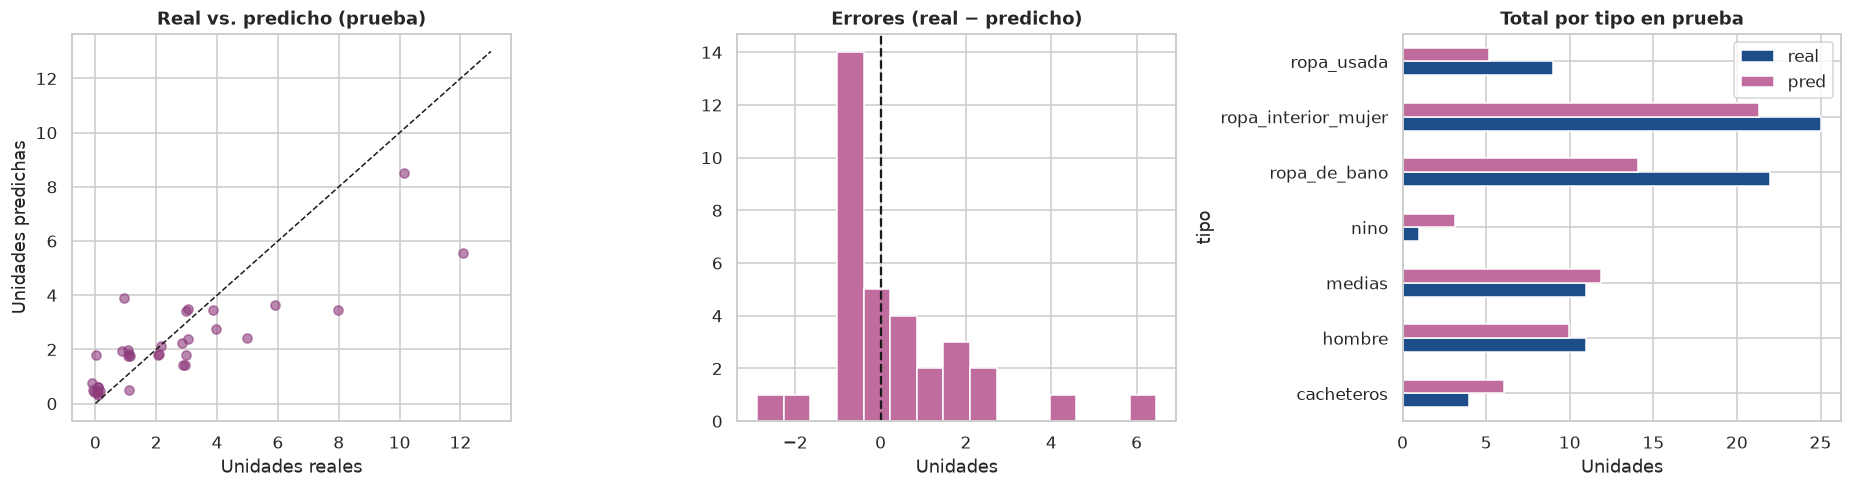

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def metricas(y_real, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    return {"RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))), "MAE": float(mean_absolute_error(y_real, y_pred)), "R2": float(r2_score(y_real, y_pred))}

ref_pipe = armar(DummyRegressor(strategy="mean")).fit(X_tr, y_tr)
m_ref = metricas(y_te, ref_pipe.predict(X_te))
m_mej = metricas(y_te, MEJOR.predict(X_te))
tabla_test = pd.DataFrame([m_ref, m_mej], index=["Referencia (promedio)", NOMBRE_MEJOR + " (optimizado)"]).reset_index().rename(columns={"index": "Modelo"})
tabla_test.to_csv(OUT / "metricas_test.csv", index=False)
mostrar(tabla_test.round(3), 160)

pred = np.clip(MEJOR.predict(X_te), 0, None)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
rng = np.random.default_rng(RANDOM_STATE)
ax[0].scatter(y_te + rng.uniform(-.15, .15, len(y_te)), pred, alpha=.6, color="#8e3b7c")
lim = max(y_te.max(), pred.max()) + 1; ax[0].plot([0, lim], [0, lim], "k--", lw=1)
ax[0].set_xlabel("Unidades reales"); ax[0].set_ylabel("Unidades predichas"); ax[0].set_title("Real vs. predicho (prueba)")
ax[1].hist(y_te - pred, bins=15, color="#c06c9f", edgecolor="white"); ax[1].axvline(0, color="k", ls="--")
ax[1].set_title("Errores (real − predicho)"); ax[1].set_xlabel("Unidades")
por_tipo = pd.DataFrame({"tipo": X_te["tipo"].values, "real": y_te.values, "pred": pred}).groupby("tipo")[["real", "pred"]].sum()
por_tipo.plot.barh(ax=ax[2], color=["#1d4e89", "#c06c9f"]); ax[2].set_title("Total por tipo en prueba"); ax[2].set_xlabel("Unidades")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br><b>Izquierda:</b> cada punto es una fila de prueba; si el modelo fuera perfecto, caerían sobre la línea punteada. <b>Centro:</b> los errores deben concentrarse cerca de 0 y sin sesgo hacia un solo lado. <b>Derecha:</b> si el total por tipo se parece al real. Con tan pocos datos se esperan errores visibles: lo importante es que el modelo <b>supere al de referencia</b>.</div>

In [12]:
mejora_test = (1 - m_mej["RMSE"] / m_ref["RMSE"]) * 100
nota("Lectura automática", f"En días nunca vistos, el modelo elegido tiene RMSE = <b>{m_mej['RMSE']:.2f}</b>, MAE = <b>{m_mej['MAE']:.2f}</b> y R² = <b>{m_mej['R2']:.2f}</b>; "
     f"el modelo de referencia tiene RMSE = {m_ref['RMSE']:.2f} y R² = {m_ref['R2']:.2f}. La mejora en RMSE es de <b>{mejora_test:.0f} %</b>. "
     + ("El modelo aporta información respecto al promedio." if mejora_test > 0 else "<b>El modelo NO supera al promedio en prueba</b>: hay que decirlo así en la defensa."),
     "#0b6e4f" if mejora_test > 0 else "#b32024", "✅" if mejora_test > 0 else "⚠️")

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br><b>Importancia de las variables.</b> Se usa <i>importancia por permutación</i>: se desordena una variable de prueba y se mide cuánto empeora el error. Cuanto más empeora, más depende el modelo de ella.</div>

,Variable,Aumento del RMSE,±
2,tipo,1.409,0.169
3,mes,0.358,0.185
0,lugar_venta,0.073,0.032
4,semana_iso,0.009,0.121
1,dia_semana,-0.002,0.009
5,calor,-0.058,0.028


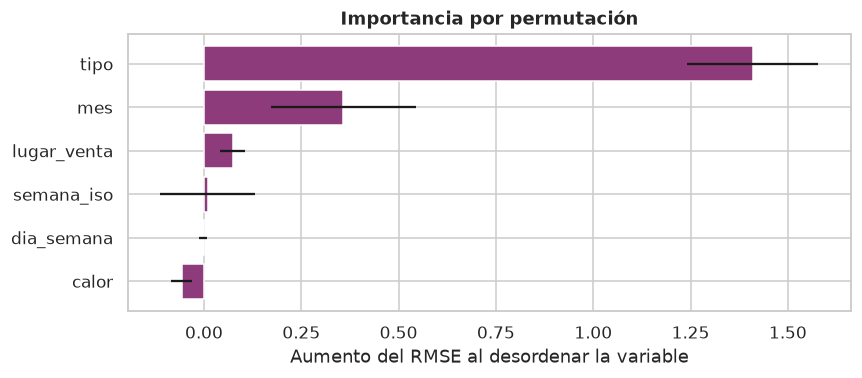

In [13]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(MEJOR, X_te, y_te, scoring="neg_root_mean_squared_error", n_repeats=30, random_state=RANDOM_STATE)
tabla_imp = pd.DataFrame({"Variable": FEATS, "Aumento del RMSE": imp.importances_mean, "± ": imp.importances_std}).sort_values("Aumento del RMSE", ascending=False)
mostrar(tabla_imp.round(3), 220)
plt.figure(figsize=(8, 3.6)); t = tabla_imp.sort_values("Aumento del RMSE")
plt.barh(t["Variable"], t["Aumento del RMSE"], xerr=t["± "], color="#8e3b7c"); plt.xlabel("Aumento del RMSE al desordenar la variable")
plt.title("Importancia por permutación"); plt.tight_layout(); plt.show()

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Las barras más largas son las variables de las que más depende el modelo. Un valor cerca de 0 (o negativo) significa que esa variable no aporta. Recordar que lugar, mes, día y calor están mezclados entre sí (sección 5): la importancia de una puede estar «prestada» por otra.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 9. Exportación del pipeline a .joblib</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se guarda en un solo archivo un diccionario con el <b>pipeline completo</b> (codificación, escalado y modelo) y los metadatos para usarlo después: variables, tipos, lugares, fecha de inicio de la temporada de calor, fecha de inicio de cada tipo, métricas y la versión de scikit-learn. Luego se <b>vuelve a cargar y se verifica</b> que dé exactamente las mismas predicciones.</div>

In [14]:
M = {
    "pipeline": MEJOR,
    "nombre_modelo": NOMBRE_MEJOR,
    "hiperparametros": {k.replace("modelo__", ""): v for k, v in busquedas[NOMBRE_MEJOR].best_params_.items()},
    "features": FEATS, "features_cat": FEATS_CAT, "features_num": FEATS_NUM, "features_bin": FEATS_BIN,
    "dias": DIAS,
    "tipos": sorted(diario["tipo"].unique()),
    "lugares": sorted(diario["lugar_venta"].unique()),
    "fecha_calor": str(FECHA_CALOR.date()),
    "inicio_tipo": {r.tipo: str(r.inicio.date()) for r in inicio.itertuples()},
    "rango_entrenamiento": (str(diario["fecha"].min().date()), str(diario["fecha"].max().date())),
    "metricas_test": m_mej, "metricas_referencia_test": m_ref,
    "metricas_cv": {"RMSE": float(tabla_opt.loc[0, "Mejor RMSE (CV)"])},
    "sklearn_version": sklearn.__version__,
    "origen_datos": "ESTIMADAS (reconstruidas): agosto a noviembre de 2026. No son ventas reales registradas por el sistema.",
}
joblib.dump(M, "modelo_ventas.joblib", compress=3)

M2 = joblib.load("modelo_ventas.joblib")
assert np.allclose(M2["pipeline"].predict(X_te), MEJOR.predict(X_te)), "El modelo recargado no coincide con el original"
tam = Path("modelo_ventas.joblib").stat().st_size / 1024
print(f"✔ modelo_ventas.joblib guardado ({tam:,.0f} KB) y verificado: el modelo recargado da las mismas predicciones.")
print("Contenido:", ", ".join(M2.keys()))

✔ modelo_ventas.joblib guardado (35 KB) y verificado: el modelo recargado da las mismas predicciones.
Contenido: pipeline, nombre_modelo, hiperparametros, features, features_cat, features_num, features_bin, dias, tipos, lugares, fecha_calor, inicio_tipo, rango_entrenamiento, metricas_test, metricas_referencia_test, metricas_cv, sklearn_version, origen_datos


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>El archivo <code>modelo_ventas.joblib</code> es lo que se entrega junto con el dataset y los notebooks. El notebook <code>Inferencia_Ventas_Lizzy.ipynb</code> lo carga <b>sin reentrenar</b>. Si se usa otra versión de scikit-learn al cargarlo, puede avisar o fallar: por eso se guarda la versión y está en <code>requirements.txt</code>.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 10. Conclusiones y limitaciones</div>

In [15]:
nota("Resumen del trabajo", f"<ul><li>Se construyó una tabla diaria de <b>{len(diario)}</b> filas (día × lugar × tipo, con ceros) a partir de <b>{len(lineas)}</b> líneas de pedido.</li>"
     f"<li>Se compararon 4 modelos con validación cruzada por días y se optimizaron 3; el elegido fue <b>{NOMBRE_MEJOR}</b>.</li>"
     f"<li>En prueba: RMSE = <b>{m_mej['RMSE']:.2f}</b>, MAE = <b>{m_mej['MAE']:.2f}</b>, R² = <b>{m_mej['R2']:.2f}</b> (referencia: RMSE = {m_ref['RMSE']:.2f}).</li>"
     f"<li>El pipeline completo quedó exportado en <code>modelo_ventas.joblib</code> y se usa desde el notebook de inferencia.</li></ul>", "#0b6e4f", "✅")

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Limitaciones (decirlas antes de que las pregunten)</b><br><ol><li><b>Los datos son estimados.</b> Las ventas se reconstruyeron con reglas definidas por la autora; el modelo aprende esas reglas. No se puede afirmar que prediga ventas reales.</li><li><b>Pocos datos:</b> unas 29 jornadas y poco más de 300 líneas. Las métricas varían mucho según qué días caigan en prueba.</li><li><b>Variables mezcladas:</b> lugar, mes, día de la semana y temporada de calor casi coinciden entre sí (Lourdes solo en agosto, Barrio Nuevo solo los martes desde septiembre).</li><li><b>Fuera del rango:</b> el modelo se entrenó con fechas del 3 de agosto al 17 de noviembre de 2026; predecir fechas muy posteriores (por ejemplo, diciembre) es extrapolar.</li><li><b>Trabajo futuro:</b> reentrenar con ventas registradas por el sistema una vez que haya meses de uso real.</li></ol></div>